# giFBA vs. dFBA: Hyperparameters and Equivalence Scores

Efficiency and MAE/RPE analysis against the benchmark hyperparameters. Reads the preprocessed `data/{name}/hyperparams_{name}.csv` and `model_names_{name}.csv` written by `process_results.py`, so the raw JSON and flux dicts are never touched here.

Flux-level comparisons live in `4_3_compare_AH_BI_fluxes.ipynb` and `4_4_compare_N_orgs_fluxes.ipynb`. Shared helpers are in `benchmark_analysis_utils.py`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import seaborn as sns
import tol_colors as tol

import benchmark_analysis_utils as bau

## 1. Pick the experiment

In [2]:
# The one line to edit when switching datasets.
ACTIVE_CONFIG_NAME = "N_orgs"  # "AH_BI" or "N_orgs"

config = bau.PRESETS[ACTIVE_CONFIG_NAME]
DATA_DIR = Path("data") / config.name
FIG_DIR = Path("../../figures/real_model_figs/dfba_benchmark")
FIG_DIR.mkdir(parents=True, exist_ok=True)

missing = [
    p for p in (
        DATA_DIR / f"hyperparams_{config.name}.csv",
        DATA_DIR / f"model_names_{config.name}.csv",
        DATA_DIR / f"fluxes_{config.name}.pkl",
    )
    if not p.exists()
]
if missing:
    raise FileNotFoundError(
        f"Missing processed files {[str(p) for p in missing]}; "
        f"run `python process_results.py --config {config.name}` first."
    )
config

ExperimentConfig(name='N_orgs', results_dir='Benchmark_N_orgs', max_time_s=86400, binning={'vmax': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'km': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.1f}', zero_floor=False), 'early_stop_window': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'early_stop_tol': BinSpec(spread='log', bins=3, min=None, max=None, fmt_bins='{:.1e}', zero_floor=False), 'rel_abund': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.2f}', zero_floor=False), 'y0_factor': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True), 'y0_offset': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True)})

## 2. Load processed results

In [3]:
df = pd.read_csv(DATA_DIR / f"hyperparams_{config.name}.csv", index_col=0)
for col in bau.present(["rel_abund_list", "media"], df):
    df[col] = df[col].map(json.loads)

model_names = pd.read_csv(DATA_DIR / f"model_names_{config.name}.csv", index_col=0).iloc[:, 0].map(json.loads)

# Per-run equivalence metrics written by process_results.py (see
# bau.calc_equivalence_metrics for the raw sums).
EQ_COLS = [
    "Abs_Diff_Sum", "Sum_Rel_Error", "N_nonzero_rxns", "N_rxns", "Sum_Abs_Flux",
    "gifba_abs_flux_sum", "dfba_abs_flux_sum",
    "MAE", "RPE"
]
eq_df = df[EQ_COLS].copy()

print(f"Loaded {len(df)} runs from {DATA_DIR}")
df.head()

Loaded 430 runs from data/N_orgs


,N_models,rel_abund,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,early_stop_window,early_stop_tol,...,Abs_Diff_Sum,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE,RPE,RPE_abs
run_id,,,,,,,,,,,,,,,,,,,,,
5906512_1,4,0.113436,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",7489,6790,19.179103,0.120450,BDF,20,1.000000e-07,...,13.906465,17.409310,133,7489,307.817473,153.894936,153.922536,0.001857,0.002325,0.002325
5912065_1,9,0.055533,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",15760,14262,11.768120,0.432876,BDF,20,1.000000e-07,...,35.322745,2.583354,4120,15760,269.127516,128.444733,140.682783,0.002241,0.000164,0.000164
5912065_10,9,0.050241,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",17718,15637,55.908102,0.792483,RK45,20,1.000000e-07,...,13.203588,117.162417,2297,17718,259.226305,130.900421,128.325884,0.000745,0.006613,0.006613
5912065_100,8,0.058220,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",13613,12040,22.051307,0.178865,BDF,20,1.000000e-07,...,12.179044,-58.555883,581,13613,221.611803,112.108170,109.503634,0.000895,-0.004301,0.004301
5912065_101,9,0.050154,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",11778,10806,20.092330,0.911163,RK45,20,1.000000e-07,...,61.380406,-36.528021,3934,11778,332.074038,155.931438,176.142600,0.005211,-0.003101,0.003101


## 4. Split giFBA / dFBA column subsets

In [4]:
gifba_cols = bau.present(bau.GIFBA_COLS, df)
dfba_cols = bau.present(bau.DFBA_COLS, df)

gifba_df = df[gifba_cols].copy()
dfba_df = df[dfba_cols].copy()

print("giFBA columns:", gifba_cols)
print("dFBA columns:", dfba_cols)

giFBA columns: ['N_models', 'sum_N_rxns', 'sum_N_mets', 'rel_abund', 'log10_time_ratio', 'log10_pfba_call_ratio', 'gifba_solve_time', 'gifba_pfba_calls']
dFBA columns: ['N_models', 'sum_N_rxns', 'sum_N_mets', 'rel_abund', 'vmax', 'km', 'solver_method', 'early_stop_window', 'early_stop_tol', 'log10_time_ratio', 'log10_pfba_call_ratio', 'dfba_solve_time', 'dfba_pfba_calls']


## 5. Efficiency violin plots (log10 time / pFBA-call ratios)

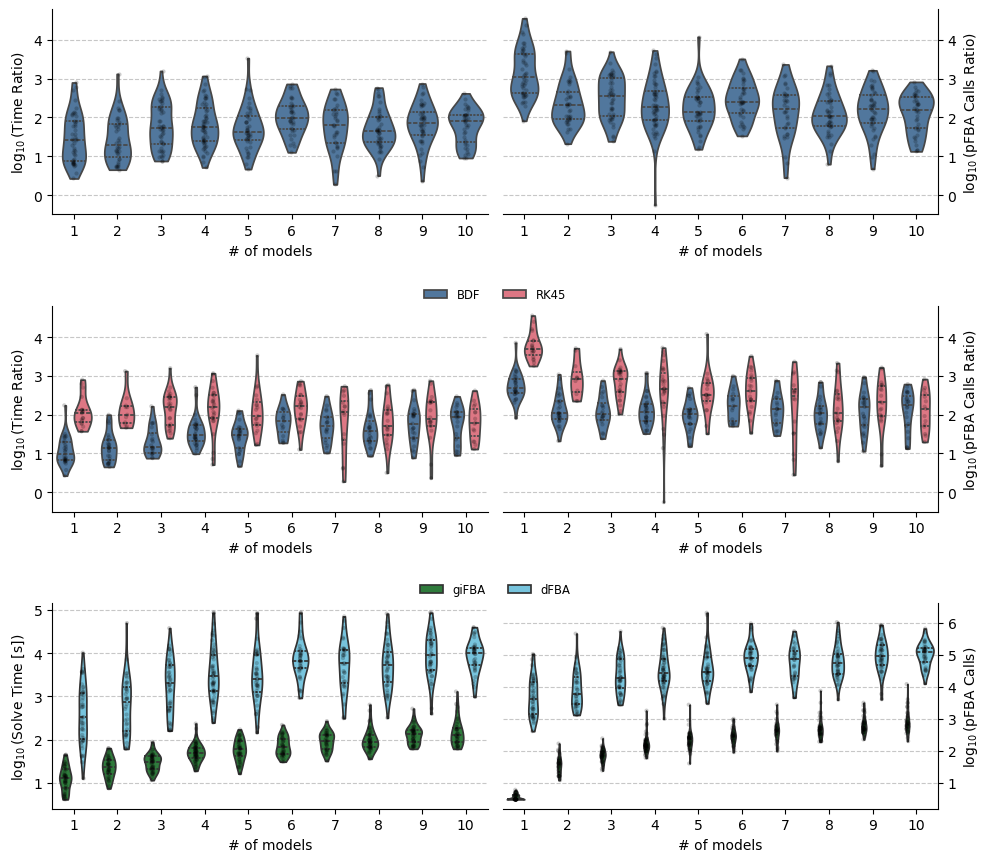

In [5]:
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=tol.bright)

Y_SCALE = "linear"

# Only evaluate groupings whose columns actually exist for this experiment
# (e.g. the N_orgs preset has no y0_factor_binned/y0_offset_binned).
vars_eval = [g for g in bau.VARS_EVAL if all(c in dfba_df.columns for c in g)]

y_min, y_max = (
    dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].min().min(),
    dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].max().max(),
)
y_range = y_max - y_min
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

# One extra row at the bottom compares raw giFBA vs. dFBA solve costs.
n_rows = len(vars_eval) + 1
fig, axs = plt.subplots(n_rows, 2, figsize=(10, 3 * n_rows))
axs = axs.flatten()

for row, groupby_cols in enumerate(vars_eval):
    bau.plot_subgrouped(dfba_df, groupby_cols, row, axs, y_min, y_max, y_scale=Y_SCALE)
    
bau.plot_subgrouped(df, ["N_models"], len(vars_eval), axs, y_scale=Y_SCALE, compare_methods=True)

plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3.5)

# Place row legends
for row in range(n_rows):
    ax_left = axs[row * 2]
    ax_right = axs[row * 2 + 1]

    handles, labels = ax_left.get_legend_handles_labels()
    if handles:
        n_subgroups = len(set(labels))
        handles = handles[:n_subgroups]
        labels = labels[:n_subgroups]

        combined_bbox = Bbox.union([ax_left.get_position(), ax_right.get_position()])

        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(combined_bbox.x0 + combined_bbox.width / 2, combined_bbox.y1 * 0.99),
            bbox_transform=fig.transFigure,
            ncol=len(handles),
            frameon=False,
            fontsize="small",
        )
        if ax_left.get_legend() is not None:
            ax_left.get_legend().remove()

plt.savefig(FIG_DIR / f"efficiency_violin_plots_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 6. Solve cost summary table (N_orgs only)

Mean +/- standard error (number of runs) of solve time and pFBA calls per community size. The LaTeX version swaps "+/-" for `$\pm$` and is saved next to the figures.

In [8]:
def fmt_mean_se(values: pd.Series) -> str:
    """Format as 'mean +/- SE (n)', rounding both to the SE's second significant figure.

    Values of 1,000 or more switch both numbers to thousands, e.g. '4.3K +/- 0.5K (n)'.
    """
    values = values.dropna()
    n = len(values)
    if n == 0:
        return "--"
    mean = values.mean()
    if n == 1:
        return f"{mean / 1000:,.1f}K (1)" if abs(mean) >= 1000 else f"{mean:.3g} (1)"
    se = values.std(ddof=1) / np.sqrt(n)
    if max(abs(mean), se) >= 1000:
        return f"{mean / 1000:,.1f}K +/- {se / 1000:,.1f}K ({n})"
    decimals = max(0, 1 - int(np.floor(np.log10(se)))) if se > 0 else 0
    return f"{mean:,.{decimals}f} +/- {se:,.{decimals}f} ({n})"


if config.name != "N_orgs":
    print(f"Summary table is only built for N_orgs; skipping for {config.name}.")
else:
    # dFBA runs still in progress when the job hit its wall-time limit have
    # their solve time clamped to the limit and a truncated pFBA count, so they
    # are dropped from the dFBA columns. Every run also did its own giFBA
    # solve, which doesn't depend on the dFBA solver, so giFBA keeps all rows.
    dfba_done = df["dfba_status"] == "dfba_complete"
    print(f"Excluded {(~dfba_done).sum()} unfinished dFBA run(s) from the dFBA columns:")
    print(df.loc[~dfba_done, ["N_models", "solver_method", "dfba_status"]].to_string())

    # metrics = {"Solve Time (s)": "solve_time", "pFBA Calls": "pfba_calls"}
    metrics = {"pFBA Calls": "pfba_calls"}
    row_groups = [(str(n), df["N_models"] == n) for n in sorted(df["N_models"].unique())]
    row_groups.append(("Total", pd.Series(True, index=df.index)))

    summary = {}
    for metric, suffix in metrics.items():
        subsets = {
            "giFBA": df[f"gifba_{suffix}"],
            "dFBA (BDF)": df.loc[dfba_done & (df["solver_method"] == "BDF"), f"dfba_{suffix}"],
            "dFBA (RK45)": df.loc[dfba_done & (df["solver_method"] == "RK45"), f"dfba_{suffix}"],
        }
        for method, values in subsets.items():
            summary[(metric, method)] = {
                label: fmt_mean_se(values[mask.reindex(values.index)]) for label, mask in row_groups
            }

    summary_table = pd.DataFrame(summary)
    summary_table.columns = pd.MultiIndex.from_tuples(summary_table.columns)
    summary_table.index.name = "N organisms"
    display(summary_table)

    latex = summary_table.to_latex(multicolumn=True, multicolumn_format="c", column_format="l" + "r" * 6)
    latex = latex.replace("+/-", r"$\pm$")
    (FIG_DIR / f"solve_cost_table_{config.name}.tex").write_text(latex)
    print(latex)

Excluded 7 unfinished dFBA run(s) from the dFBA columns:
             N_models solver_method               dfba_status
run_id                                                       
5912065_103         4          RK45   dfba_in_progress_704000
5912065_165         6          RK45   dfba_in_progress_967500
5912065_170         9          RK45   dfba_in_progress_774000
5912065_198         4          RK45     dfba_in_progress_1000
5912065_2           6          RK45   dfba_in_progress_736500
5912065_461         9           BDF   dfba_in_progress_819000
5912065_55          5          RK45  dfba_in_progress_1788500


pFBA Calls                                               
                          giFBA             dFBA (BDF)             dFBA (RK45)
N organisms                                                                   
1            3.51 +/- 0.11 (47)     2.9K +/- 0.7K (28)     28.3K +/- 7.0K (19)
2             43.5 +/- 5.1 (38)     7.1K +/- 1.6K (27)    71.4K +/- 39.7K (11)
3             78.4 +/- 5.6 (46)    10.4K +/- 2.2K (20)    82.0K +/- 20.5K (26)
4               201 +/- 32 (58)   36.4K +/- 13.1K (31)   102.2K +/- 18.2K (25)
5               299 +/- 63 (43)    27.5K +/- 5.5K (24)  205.3K +/- 112.4K (18)
6               341 +/- 35 (37)   58.4K +/- 11.2K (15)   145.3K +/- 29.8K (20)
7               547 +/- 89 (34)   67.5K +/- 14.5K (18)   154.6K +/- 40.8K (16)
8              742 +/- 176 (44)  110.5K +/- 46.1K (23)   137.5K +/- 34.1K (21)
9               787 +/- 92 (45)  109.8K +/- 21.2K (24)   176.7K +/- 44.5K (19)
10           1.3K +/- 0.3K (38)  126.1K +/- 22.2K (23)   171.2K +/- 41.7K (15)
Total          416 +/- 41 (430)   53.4K +/- 6.5K (233)  125.8K +/- 14.2K (190)

\begin{tabular}{lrrrrrr}
\toprule
 & \multicolumn{3}{c}{pFBA Calls} \\
 & giFBA & dFBA (BDF) & dFBA (RK45) \\
N organisms &  &  &  \\
\midrule
1 & 3.51 $\pm$ 0.11 (47) & 2.9K $\pm$ 0.7K (28) & 28.3K $\pm$ 7.0K (19) \\
2 & 43.5 $\pm$ 5.1 (38) & 7.1K $\pm$ 1.6K (27) & 71.4K $\pm$ 39.7K (11) \\
3 & 78.4 $\pm$ 5.6 (46) & 10.4K $\pm$ 2.2K (20) & 82.0K $\pm$ 20.5K (26) \\
4 & 201 $\pm$ 32 (58) & 36.4K $\pm$ 13.1K (31) & 102.2K $\pm$ 18.2K (25) \\
5 & 299 $\pm$ 63 (43) & 27.5K $\pm$ 5.5K (24) & 205.3K $\pm$ 112.4K (18) \\
6 & 341 $\pm$ 35 (37) & 58.4K $\pm$ 11.2K (15) & 145.3K $\pm$ 29.8K (20) \\
7 & 547 $\pm$ 89 (34) & 67.5K $\pm$ 14.5K (18) & 154.6K $\pm$ 40.8K (16) \\
8 & 742 $\pm$ 176 (44) & 110.5K $\pm$ 46.1K (23) & 137.5K $\pm$ 34.1K (21) \\
9 & 787 $\pm$ 92 (45) & 109.8K $\pm$ 21.2K (24) & 176.7K $\pm$ 44.5K (19) \\
10 & 1.3K $\pm$ 0.3K (38) & 126.1K $\pm$ 22.2K (23) & 171.2K $\pm$ 41.7K (15) \\
Total & 416 $\pm$ 41 (430) & 53.4K $\pm$ 6.5K (233) & 125.8K $\pm$ 14.2K (190) \\
\bottomru

## 7. MAE / RPE distributions

12 run(s) had exact-zero MAE; excluded from the log-scale histogram.


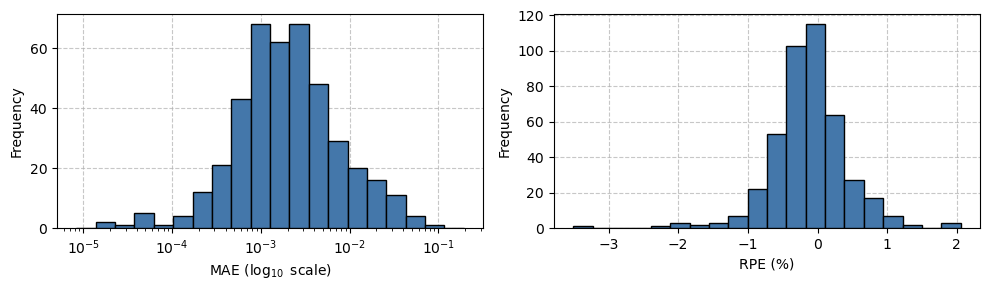

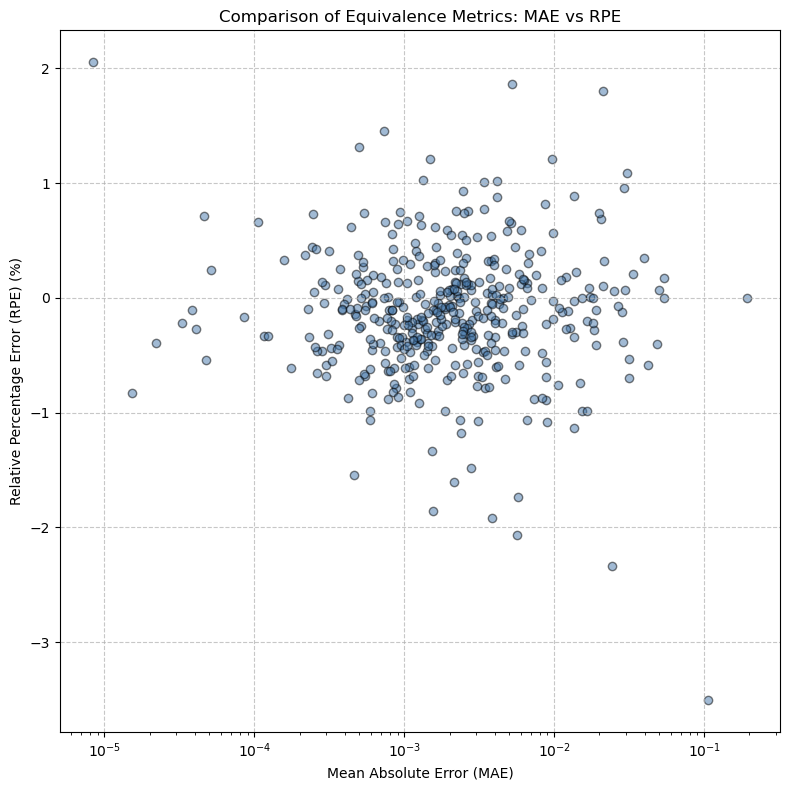

In [7]:
n_bins = 20

# A run where giFBA and dFBA fluxes match exactly (MAE == 0) has no finite
# log10, so it is left out of the log-scale histogram and percentiles.
mae = eq_df["MAE"]
rpe = eq_df["RPE"]

zero_mae_count = int((mae == 0).sum())
if zero_mae_count:
    print(f"{zero_mae_count} run(s) had exact-zero MAE; excluded from the log-scale histogram.")

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

bin_edges = np.logspace(np.log10(mae[mae > 0].min()), np.log10(mae.max()), n_bins + 1)
axs[0].hist(mae[mae > 0], bins=bin_edges, edgecolor="black", zorder=3)
axs[0].set_xlabel(r"MAE ($\log_{10}$ scale)")
axs[0].set_ylabel("Frequency")
axs[0].set_xscale("log")

axs[1].hist(rpe * 100, bins=n_bins, edgecolor="black", zorder=3)
axs[1].set_xlabel("RPE (%)")
axs[1].set_ylabel("Frequency")

for ax in axs:
    ax.grid(axis="both", linestyle="--", alpha=0.7, zorder=0)
plt.tight_layout()
plt.savefig(FIG_DIR / f"mae_rpe_histograms_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

nonzero_mae = eq_df[eq_df["MAE"] > 0]
plt.figure(figsize=(8, 8))
plt.scatter(nonzero_mae["MAE"], nonzero_mae["RPE"] * 100, alpha=0.5, edgecolor="k")
plt.xscale("log")
plt.xlabel("Mean Absolute Error (MAE)")
plt.ylabel("Relative Percentage Error (RPE) (%)")
plt.title("Comparison of Equivalence Metrics: MAE vs RPE")
plt.grid(axis="both", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(FIG_DIR / f"mae_v_rpe_scatter_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()